---
<h1 style="text-align: center;"><strong>Data Science & Statistical Computing</strong></h1>
<h2 style="text-align: center;"><strong>CheckPoint05</strong></h2>
<h3 style="text-align: center;"><strong>Random Forest, XGBoost e LightGBM: modelagem, tuning, avaliação e deploy</strong></h3>
<h4 style="text-align: center;"><strong>Versão única</strong></h4>

<style>
.jp-MarkdownOutput, .text_cell_render {
    font-family: "Latin Modern Roman", "CMU Serif", Georgia, "DejaVu Serif", serif;
    font-size: 18px;
    line-height: 1.6;
}
.jp-MarkdownOutput p, .text_cell_render p,
.jp-MarkdownOutput li, .text_cell_render li {
    line-height: 1.6;
}
</style>

<div style="border-left: 4px solid #666; padding: 10px 16px; margin: 18px 0;">
<strong>Configuração visual:</strong> o notebook prioriza tipografia serifada para células Markdown. A renderização de CSS pode variar entre Jupyter Notebook, JupyterLab, VS Code e Google Colab; quando uma fonte não estiver disponível, o visualizador utilizará uma alternativa local. O código permanece com fonte monoespaçada do ambiente.
</div>

<br>

---

<br>

## **Identificação dos alunos**

A atividade deve ser realizada em **grupos de no máximo 5 alunos**. Preencha, abaixo, o nome e o RM de cada integrante do grupo. Caso o grupo tenha menos de cinco integrantes, mantenha sem preenchimento os campos não utilizados.


In [1]:
#@title Identificação
Nome_1 = "João Vitor Piccolo" #@param {type:"string"}
RM_1 = "565127" #@param {type:"string"}
Nome_2 = "Gabrielle Calazans" #@param {type:"string"}
RM_2 = "564460" #@param {type:"string"}
Nome_3 = "Jéssica Domingues" #@param {type:"string"}
RM_3 = "562973" #@param {type:"string"}
Nome_4 = "Kauã Carvalho" #@param {type:"string"}
RM_4 = "566371" #@param {type:"string"}
Nome_5 = "Leonardo Pereira" #@param {type:"string"}
RM_5 = "561349" #@param {type:"string"}


<br>

---

<br>

# **CheckPoint05**

## **Objetivos**

- Estruturar um problema real de **classificação** ou **regressão** a partir de uma base de dados escolhida pelo grupo.
- Realizar **data wrangling**, análise exploratória e seleção justificada das variáveis preditoras.
- Implementar e comparar **Random Forest**, **XGBoost** e **LightGBM** sob o mesmo protocolo experimental.
- Ajustar hiperparâmetros com **Grid Search** e **Optuna**, sem utilizar o conjunto de teste durante a busca.
- Selecionar o melhor modelo com base em evidências quantitativas e analisar **overfitting** e **underfitting**.
- Avaliar o modelo final em dados não utilizados no desenvolvimento e construir um teste de consistência das previsões.
- Disponibilizar o projeto em um repositório **GitHub** e uma interface funcional em **Streamlit**.

## **Instruções**

- Leia cada enunciado com atenção.
- Observe a pontuação indicada em cada questão. A atividade vale **10 pontos** no total.
- O grupo deve escolher **um único problema** que possa ser tratado como classificação ou regressão e utilizar a mesma base em toda a atividade.
- A base pode ser pública, institucional autorizada ou coletada pelo grupo. A fonte, a licença ou a forma de obtenção devem ser documentadas.
- O problema deve produzir uma representação tabular de atributos e variável-alvo. Não utilize dados pessoais ou sensíveis sem autorização e justificativa acadêmica adequada.
- Sempre que necessário, registre o raciocínio antes da implementação em Python.
- Quando o item pedir interpretação, responda com base nos resultados obtidos, não apenas com definições genéricas.
- Responda os exercícios nos espaços indicados. Caso seja necessário, adicione células para complementar a resposta.
- Indique de forma organizada a solução dos exercícios.
- Preocupe-se em fazer um código Python limpo, documentado e reprodutível. Esse aspecto será avaliado ao longo de toda a atividade.
- O conjunto de **teste deve permanecer isolado** durante seleção de variáveis, comparação de modelos e tuning. Ele só poderá ser utilizado no Exercício 7.
- O envio da atividade deve incluir o notebook `.ipynb`, o link do repositório GitHub e o link da aplicação Streamlit.
- Cada grupo deverá realizar uma **apresentação oral da solução, com duração máxima de 10 minutos**, sintetizando o problema, as principais decisões metodológicas, a comparação entre os modelos, o modelo final e a demonstração da aplicação.
- Execute o notebook do início ao fim antes do envio. Ele não deve conter erros durante a execução.

<div style="border-left: 4px solid #666; padding: 10px 16px; margin: 18px 0;">
<strong>Entregáveis obrigatórios:</strong> notebook final, repositório GitHub reproduzível, aplicação Streamlit funcional e **apresentação oral da solução com duração máxima de 10 minutos**. O repositório deve conter, no mínimo, README com instruções de execução, arquivo de dependências, código da aplicação e os arquivos necessários para reproduzir o treinamento ou carregar o modelo final.
</div>

In [2]:
# imports e configuração visual do notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib import font_manager

fontes_preferidas = [
    "Latin Modern Roman",
    "CMU Serif",
    "Georgia",
    "DejaVu Serif",
]

fonte_serif = "DejaVu Serif"
for fonte in fontes_preferidas:
    try:
        font_manager.findfont(fonte, fallback_to_default=False)
        fonte_serif = fonte
        break
    except Exception:
        pass

sns.set_theme(style="whitegrid", palette="viridis")

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [fonte_serif, "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "text.usetex": False,
    "figure.figsize": (9, 5),
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.7,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
})

print(f"Fonte serifada selecionada para os gráficos: {fonte_serif}")

Fonte serifada selecionada para os gráficos: Georgia


<br>

---

<br>

## **Notação utilizada na atividade**

Considere a base de dados como

$$
\mathcal{D}=\{(\mathbf{x}_i,y_i)\}_{i=1}^{n},
$$

em que $\mathbf{x}_i$ representa as variáveis preditoras da observação $i$ e $y_i$ representa a variável-alvo. Ao organizar os dados, utilize a notação

$$
\mathbf{X} \quad \text{para a matriz de atributos},
\qquad
\mathbf{y} \quad \text{para o vetor da variável-alvo}.
$$

A separação deve produzir

$$
\mathcal{D}_{\mathrm{treino}}
\quad \text{e} \quad
\mathcal{D}_{\mathrm{teste}},
$$

sendo $\mathcal{D}_{\mathrm{teste}}$ mantido fora de todo o processo de seleção e tuning. Os três modelos serão indicados por

$$
M_{\mathrm{RF}},
\qquad
M_{\mathrm{XGB}},
\qquad
M_{\mathrm{LGBM}}.
$$

As previsões serão representadas por $\hat{\mathbf{y}}$. Para hiperparâmetros, utilize $\boldsymbol{\theta}$ e registre os melhores valores encontrados por cada estratégia de busca.

<br>

---

<br>

## **Exercícios propostos**

A atividade foi organizada como um fluxo completo de desenvolvimento de um projeto de machine learning. Os sete exercícios devem ser respondidos em sequência, pois as decisões tomadas nas etapas iniciais serão utilizadas nas etapas seguintes.

<br>

---

<br>

### **Exercício 1 — Definição do problema e da base de dados — 1,0 ponto**

Escolha um problema real que possa ser tratado por **Random Forest**, **XGBoost** e **LightGBM**. O problema pode ser de classificação ou regressão.

1. **Contexto e problema — 0,25 ponto.** Descreva o contexto, a pergunta que será respondida e por que uma solução preditiva é adequada.
2. **Variável-alvo — 0,25 ponto.** Defina $y$, informe se o problema é de classificação ou regressão e explique o significado da previsão $\hat{y}$ no domínio escolhido.
3. **Base de dados — 0,25 ponto.** Informe a fonte, o método de obtenção, o número inicial de linhas e colunas, a unidade observacional e as principais variáveis disponíveis.
4. **Critério de sucesso — 0,25 ponto.** Defina a métrica principal que será usada para comparar os modelos e justifique a escolha. Métricas auxiliares podem ser utilizadas, mas deve existir uma métrica principal comum aos três algoritmos.

**Sugestões de apoio visual:** tabela com dicionário de dados, gráfico da distribuição da variável-alvo e, quando aplicável, gráfico da frequência das classes.

**Resposta do aluno — Exercício 1**

### 1. Contexto e problema

O controle de qualidade de vinhos tintos combina análise química de laboratório com avaliação sensorial. Medir os 11 atributos físico-químicos é relativamente barato e reproduzível; obter a nota de um painel de especialistas é mais lento e subjetivo. A pergunta preditiva é: **dado o perfil químico de um vinho tinto, qual nota sensorial devemos esperar?**

Uma solução supervisionada é adequada porque existe um histórico tabular de pares $(\mathbf{x}_i, y_i)$ — composição química e nota — e o objetivo é aprender uma função $\hat{y}=f(\mathbf{x})$ útil para triagem, priorização de lotes e apoio à enologia. Random Forest, XGBoost e LightGBM são apropriados: lidam com relações não lineares e interações entre álcool, acidez e sulfatos sem exigir especificação manual dessas interações.

### 2. Variável-alvo

- $\mathbf{y} = \texttt{quality}$: nota sensorial inteira na escala usual de 0 a 10. Nesta base aparecem os valores **3 a 8**.
- O problema é tratado como **regressão**. A nota é ordinal e numericamente interpretável: errar 5 vs. 6 é menos grave do que errar 5 vs. 8. A regressão preserva essa escala; uma classificação multiclasse ignoraria a distância entre notas e sofreria com classes raras (3 e 8).
- $\hat{y}$ é a **nota prevista** no mesmo eixo. Na prática, $\hat{y}=6{,}3$ indica um vinho intermediário, mais próximo de 6 do que de 5.

### 3. Base de dados

- **Fonte:** *Wine Quality* (vinho tinto) do repositório UCI, trabalho de Cortez et al. (2009), licença de uso acadêmico público.
- **Obtenção:** arquivo local `winequality-red.csv` (separador vírgula).
- **Dimensões iniciais:** 1.599 linhas $\times$ 12 colunas (11 preditores + alvo).
- **Unidade observacional:** uma amostra de vinho tinto *vinho verde* caracterizada por um vetor químico e uma nota.
- **Variáveis:** acidez fixa e volátil, ácido cítrico, açúcar residual, cloretos, dióxido de enxofre livre e total, densidade, pH, sulfatos, álcool e `quality`.

O código abaixo apresenta o dicionário de dados, o resumo descritivo e a distribuição de $y$. As notas **5 e 6 dominam**; 3 e 8 são raras. Isso será respeitado no split estratificado e na escolha da métrica.

### 4. Critério de sucesso

- **Métrica principal:** RMSE, em pontos da nota. Permanece na mesma unidade de $y$, penaliza erros grandes (prever 8 para um vinho 5) e é a métrica usada nas Aulas 18–20, o que mantém comparabilidade pedagógica.
- **Auxiliares:** MAE (erro típico, mais robusto a outliers) e $R^2$ (fração da variância de $y$ explicada).
- Os três algoritmos serão comparados **sempre** por RMSE de validação cruzada em $\mathcal{D}_{\mathrm{treino}}$. O teste só entra no Exercício 7.

Dimensões iniciais: (1599, 12)

Primeiras linhas:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5



Tipos de dados:


,dtype
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64



Frequência da variável-alvo quality:


,quality,frequencia,proporcao
0,3,10,0.006254
1,4,53,0.033146
2,5,681,0.425891
3,6,638,0.398999
4,7,199,0.124453
5,8,18,0.011257



Resumo descritivo:


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000



Dicionário de dados:


,variavel,tipo,unidade,papel,descricao
0,fixed acidity,numérica,g/ácido tartárico/L,preditora,Acidez fixa (não volátil)
1,volatile acidity,numérica,g/ácido acético/L,preditora,Acidez volátil; excesso associa-se a gosto de ...
2,citric acid,numérica,g/L,preditora,Ácido cítrico; contribui para frescor
3,residual sugar,numérica,g/L,preditora,Açúcar residual após a fermentação
4,chlorides,numérica,g/cloreto de sódio/L,preditora,Teor de cloretos / salinidade
5,free sulfur dioxide,numérica,mg/L,preditora,"SO2 livre, ação antimicrobiana e antioxidante"
6,total sulfur dioxide,numérica,mg/L,preditora,SO2 total (livre + combinado)
7,density,numérica,g/cm³,preditora,Densidade; relacionada a álcool e açúcar
8,pH,numérica,escala pH,preditora,Acidez efetiva da amostra
9,sulphates,numérica,g/sulfato de potássio/L,preditora,Sulfatos; atuam na conservação e na percepção


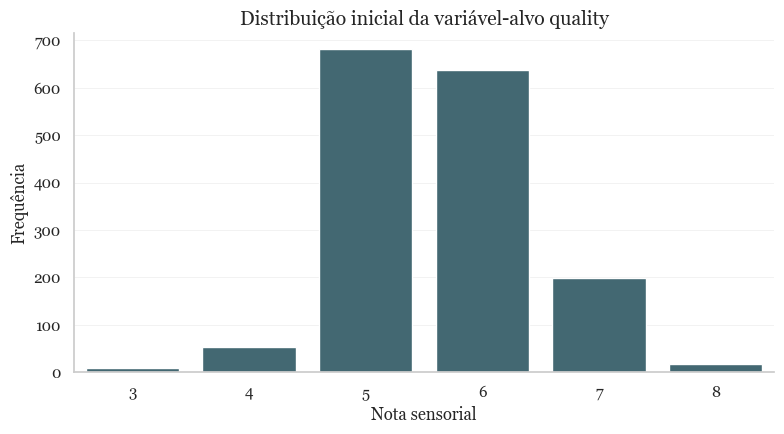

In [3]:
# Resposta do aluno - exercício 1
# Carregue a base e apresente os resumos iniciais necessários para sustentar sua descrição.

from pathlib import Path
from time import perf_counter

from sklearn.model_selection import (
    KFold,
    train_test_split,
    cross_val_score,
    GridSearchCV,
    learning_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import optuna
from optuna.samplers import TPESampler
import joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
optuna.logging.set_verbosity(optuna.logging.WARNING)

DATA_PATH = Path("winequality-red.csv")
df_raw = pd.read_csv(DATA_PATH)

print("Dimensões iniciais:", df_raw.shape)
print("\nPrimeiras linhas:")
display(df_raw.head())
print("\nTipos de dados:")
display(df_raw.dtypes.to_frame("dtype"))
print("\nFrequência da variável-alvo quality:")
freq_quality = (
    df_raw["quality"]
    .value_counts()
    .sort_index()
    .rename_axis("quality")
    .reset_index(name="frequencia")
)
freq_quality["proporcao"] = freq_quality["frequencia"] / freq_quality["frequencia"].sum()
display(freq_quality)
print("\nResumo descritivo:")
display(df_raw.describe().T)

dicionario = pd.DataFrame(
    [
        {"variavel": "fixed acidity", "tipo": "numérica", "unidade": "g/ácido tartárico/L", "papel": "preditora", "descricao": "Acidez fixa (não volátil)"},
        {"variavel": "volatile acidity", "tipo": "numérica", "unidade": "g/ácido acético/L", "papel": "preditora", "descricao": "Acidez volátil; excesso associa-se a gosto de vinagre"},
        {"variavel": "citric acid", "tipo": "numérica", "unidade": "g/L", "papel": "preditora", "descricao": "Ácido cítrico; contribui para frescor"},
        {"variavel": "residual sugar", "tipo": "numérica", "unidade": "g/L", "papel": "preditora", "descricao": "Açúcar residual após a fermentação"},
        {"variavel": "chlorides", "tipo": "numérica", "unidade": "g/cloreto de sódio/L", "papel": "preditora", "descricao": "Teor de cloretos / salinidade"},
        {"variavel": "free sulfur dioxide", "tipo": "numérica", "unidade": "mg/L", "papel": "preditora", "descricao": "SO2 livre, ação antimicrobiana e antioxidante"},
        {"variavel": "total sulfur dioxide", "tipo": "numérica", "unidade": "mg/L", "papel": "preditora", "descricao": "SO2 total (livre + combinado)"},
        {"variavel": "density", "tipo": "numérica", "unidade": "g/cm³", "papel": "preditora", "descricao": "Densidade; relacionada a álcool e açúcar"},
        {"variavel": "pH", "tipo": "numérica", "unidade": "escala pH", "papel": "preditora", "descricao": "Acidez efetiva da amostra"},
        {"variavel": "sulphates", "tipo": "numérica", "unidade": "g/sulfato de potássio/L", "papel": "preditora", "descricao": "Sulfatos; atuam na conservação e na percepção"},
        {"variavel": "alcohol", "tipo": "numérica", "unidade": "% vol", "papel": "preditora", "descricao": "Teor alcoólico"},
        {"variavel": "quality", "tipo": "numérica ordinal", "unidade": "nota 0–10", "papel": "alvo", "descricao": "Nota sensorial atribuída por especialistas"},
    ]
)
print("\nDicionário de dados:")
display(dicionario)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.countplot(data=df_raw, x="quality", color="#3b6d7a", ax=ax)
ax.set_title("Distribuição inicial da variável-alvo quality")
ax.set_xlabel("Nota sensorial")
ax.set_ylabel("Frequência")
plt.tight_layout()
plt.show()

<br>

---

<br>

### **Exercício 2 — Data wrangling e análise exploratória — 1,5 ponto**

Prepare a base para a etapa de modelagem. Toda transformação deve ser justificada e documentada.

1. **Diagnóstico de qualidade — 0,30 ponto.** Verifique tipos de dados, valores ausentes, duplicidades, categorias inconsistentes, valores impossíveis e outras anomalias relevantes.
2. **Tratamento dos dados — 0,40 ponto.** Execute o data wrangling necessário. Explique o que foi alterado, removido, imputado, convertido ou recodificado e por quê. Não remova observações ou variáveis apenas para melhorar métricas.
3. **Análise exploratória — 0,50 ponto.** Produza gráficos coerentes com o problema e interprete o que eles mostram sobre $\mathbf{X}$ e $\mathbf{y}$. A análise deve conter pelo menos três visualizações úteis ao desenvolvimento do modelo.
4. **Base final — 0,30 ponto.** Apresente as dimensões da base após o tratamento, verifique novamente ausências e duplicidades e registre quais decisões de preparação ainda precisarão ocorrer dentro do pipeline de modelagem.

**Sugestões de gráficos:** distribuição da variável-alvo; barras de valores ausentes; boxplots ou histogramas para variáveis numéricas; contagens para variáveis categóricas; matriz de correlação quando fizer sentido; relação entre variáveis importantes e o alvo.

<div style="border-left: 4px solid #666; padding: 10px 16px; margin: 18px 0;">
<strong>Atenção:</strong> qualquer transformação que aprenda parâmetros dos dados, como imputação baseada em estatísticas da amostra ou codificação aprendida, deve ser ajustada sem acesso ao conjunto de teste. Quando aplicável, faça essas etapas dentro de um pipeline.
</div>

**Resposta do aluno — Exercício 2**

### 1. Diagnóstico de qualidade

- **Tipos:** as 12 colunas já são numéricas (`float64` / `int64`). Não há categorias a recodificar.
- **Ausências:** zero valores faltantes.
- **Duplicidades:** 240 linhas idênticas (15% da base). No conjunto UCI Wine Quality isso é conhecido: a mesma amostra química/nota foi registrada mais de uma vez.
- **Valores impossíveis:** álcool, pH, densidade, acidez e SO₂ estão em faixas quimicamente plausíveis (álcool ≈ 8,4–14,9%; pH ≈ 2,7–4,0; densidade ≈ 0,99–1,00). Não há negativos indevidos.
- **Inconsistências de categoria:** não se aplicam.

### 2. Tratamento

A única transformação estrutural é **remover as 240 duplicatas antes do split**. Manter linhas idênticas faria o mesmo vinho aparecer em $\mathcal{D}_{\mathrm{treino}}$ e $\mathcal{D}_{\mathrm{teste}}$, vazando informação e inflando métricas. A remoção é decisão de qualidade e de anti-vazamento, não de perseguir RMSE.

Não imputamos, não recodificamos o alvo e não descartamos outliers: valores extremos de açúcar residual ou cloretos podem ser vinhos reais e informativos. Qualquer imputação futura (se um valor novo chegar nulo) ficará **dentro do pipeline**, ajustada só no treino.

### 3. Análise exploratória

Três visualizações sustentam a modelagem:

1. **Distribuição de `quality` após o tratamento.** Continua concentrada em 5 e 6. A regressão precisa ser lida nesse contexto: acertar a região central é fácil; as caudas 3 e 8 são raras e mais difíceis.
2. **Matriz de correlação.** `alcohol` e `sulphates` correlacionam positivamente com a nota; `volatile acidity` correlaciona negativamente — padrão clássico da literatura do vinho tinto. Há colinearidade entre `fixed acidity`, `citric acid`, `density` e `pH`. Árvores lidam com isso; por isso não removemos preditores colineares.
3. **Boxplots de `alcohol` e `volatile acidity` por nota.** Notas mais altas tendem a álcool maior e acidez volátil menor. Há sobreposição: a relação existe, mas não é determinística — daí a utilidade de um ensemble.

### 4. Base final

Após o drop: **1.359 × 12**, ainda sem ausências e sem duplicatas. O que permanece para o pipeline de modelagem é apenas um `SimpleImputer` defensivo (mediana), ajustado em cada fold / no treino, sem acesso ao teste. Não usamos scaler: RF, XGBoost e LightGBM são invariantes a escala monotônica e um scaler criaria uma etapa desnecessária comum apenas na aparência.

=== Diagnóstico de qualidade (base bruta) ===

Tipos:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

Ausências por coluna:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Linhas duplicadas: 240

Valores mínimos:
fixed acidity           4.60000
volatile acidity        0.12000
citric acid             0.00000
residual sugar          0.90000
chlorides               0.0120

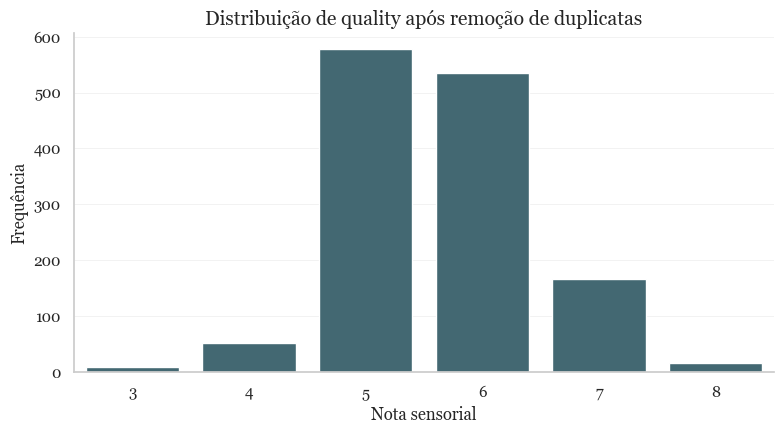

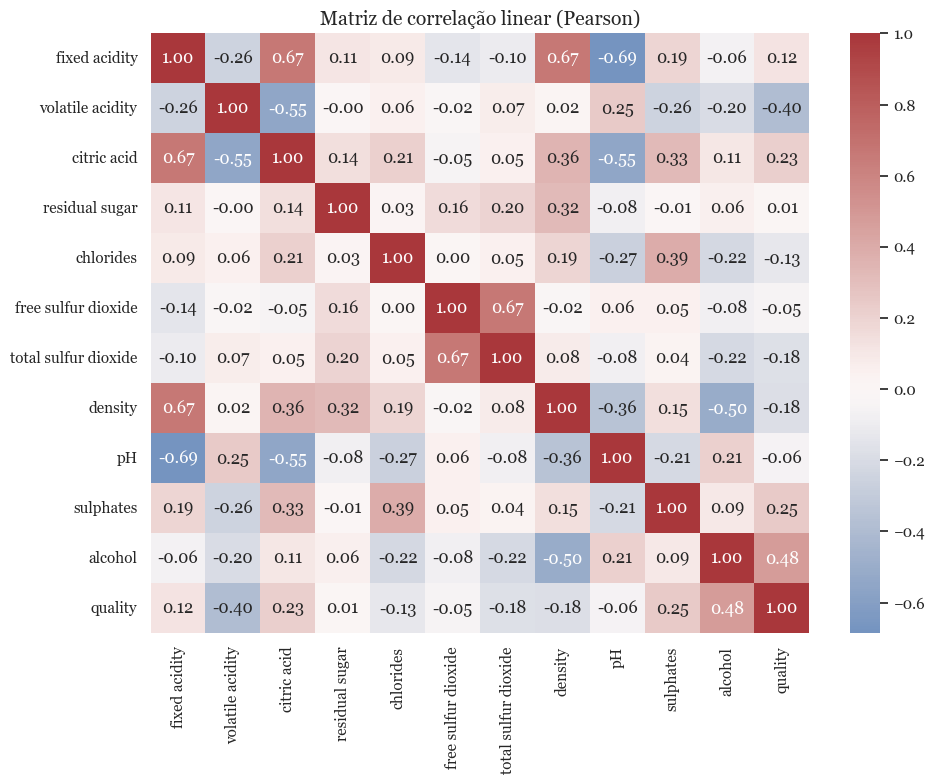

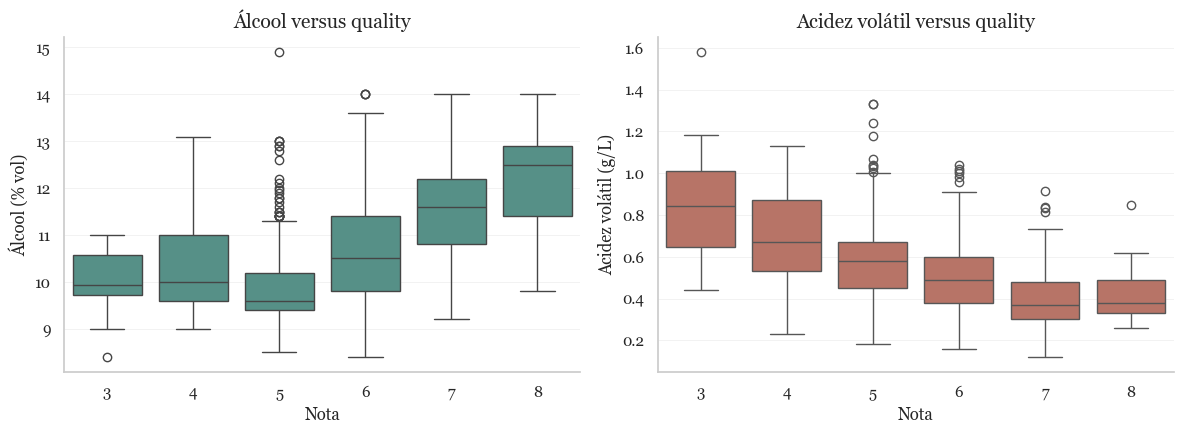


Correlação de cada preditor com quality:
                      corr_quality
alcohol                   0.480343
sulphates                 0.248835
citric acid               0.228057
fixed acidity             0.119024
residual sugar            0.013640
free sulfur dioxide      -0.050463
pH                       -0.055245
chlorides                -0.130988
total sulfur dioxide     -0.177855
density                  -0.184252
volatile acidity         -0.395214


In [4]:
# Resposta do aluno - exercício 2
# Realize o diagnóstico, o tratamento dos dados e a análise exploratória.

print("=== Diagnóstico de qualidade (base bruta) ===")
print("\nTipos:")
print(df_raw.dtypes)
print("\nAusências por coluna:")
print(df_raw.isna().sum())
print("\nLinhas duplicadas:", int(df_raw.duplicated().sum()))
print("\nValores mínimos:")
print(df_raw.min())
print("\nValores máximos:")
print(df_raw.max())

faixas_esperadas = {
    "fixed acidity": (3.0, 20.0),
    "volatile acidity": (0.0, 2.0),
    "citric acid": (0.0, 1.5),
    "residual sugar": (0.0, 20.0),
    "chlorides": (0.0, 1.0),
    "free sulfur dioxide": (0.0, 80.0),
    "total sulfur dioxide": (0.0, 300.0),
    "density": (0.98, 1.01),
    "pH": (2.5, 4.5),
    "sulphates": (0.2, 2.5),
    "alcohol": (8.0, 16.0),
    "quality": (0, 10),
}

print("\nChecagem de faixas quimicamente plausíveis:")
for col, (lo, hi) in faixas_esperadas.items():
    fora = int(((df_raw[col] < lo) | (df_raw[col] > hi)).sum())
    print(f"  {col}: {fora} valores fora de [{lo}, {hi}]")

df = df_raw.drop_duplicates().reset_index(drop=True)
print("\n=== Base após remoção de duplicatas ===")
print("Dimensões:", df.shape)
print("Ausências restantes:", int(df.isna().sum().sum()))
print("Duplicatas restantes:", int(df.duplicated().sum()))
print("\nFrequência de quality após o tratamento:")
print(df["quality"].value_counts().sort_index())

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.countplot(data=df, x="quality", color="#3b6d7a", ax=ax)
ax.set_title("Distribuição de quality após remoção de duplicatas")
ax.set_xlabel("Nota sensorial")
ax.set_ylabel("Frequência")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Matriz de correlação linear (Pearson)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=df, x="quality", y="alcohol", ax=axes[0], color="#4c9a8e")
axes[0].set_title("Álcool versus quality")
axes[0].set_xlabel("Nota")
axes[0].set_ylabel("Álcool (% vol)")
sns.boxplot(data=df, x="quality", y="volatile acidity", ax=axes[1], color="#c46b5a")
axes[1].set_title("Acidez volátil versus quality")
axes[1].set_xlabel("Nota")
axes[1].set_ylabel("Acidez volátil (g/L)")
plt.tight_layout()
plt.show()

print("\nCorrelação de cada preditor com quality:")
print(corr["quality"].drop("quality").sort_values(ascending=False).to_frame("corr_quality"))

<br>

---

<br>

### **Exercício 3 — Escolha de variáveis e desenho experimental — 1,0 ponto**

Defina formalmente o conjunto de variáveis utilizado na modelagem e estabeleça o protocolo experimental antes de treinar os algoritmos.

1. **Escolha das variáveis — 0,35 ponto.** Defina $\mathbf{X}$ e $\mathbf{y}$. Liste variáveis removidas e justifique a exclusão. Identificadores, informações disponíveis apenas depois do evento previsto e variáveis que revelem diretamente o alvo devem ser analisados como possíveis fontes de **data leakage**.
2. **Separação treino–teste e validação cruzada — 0,35 ponto.** Construa $\mathcal{D}_{\mathrm{treino}}$ e $\mathcal{D}_{\mathrm{teste}}$ com uma proporção adequada e `random_state` fixo. Em classificação, utilize estratificação quando aplicável. Defina o esquema de validação cruzada que será usado dentro de $\mathcal{D}_{\mathrm{treino}}$.
3. **Métricas — 0,30 ponto.** Registre a métrica principal e as métricas auxiliares. Explique por que elas são adequadas ao problema e como serão interpretadas.

**Referência de decisão:** para classificação, considere o balanceamento das classes ao escolher entre acurácia, precision, recall, F1, ROC-AUC ou outras métricas pertinentes. Para regressão, considere métricas como MAE, RMSE e $R^2$. A escolha deve ser justificada e mantida de forma consistente ao comparar os modelos.

<div style="border-left: 4px solid #666; padding: 10px 16px; margin: 18px 0;">
<strong>Regra experimental:</strong> os três algoritmos devem utilizar o mesmo conjunto de teste e, sempre que possível, os mesmos folds de validação cruzada e a mesma métrica principal. O conjunto de teste não pode participar do Grid Search, do Optuna ou da escolha do melhor modelo.
</div>

**Resposta do aluno — Exercício 3**

### 1. Variáveis

- $\mathbf{X}$: as 11 variáveis químico-físicas (`fixed acidity` … `alcohol`).
- $\mathbf{y}$: `quality`.
- **Nenhuma preditora foi removida.** Não há identificador de amostra, timestamp, nem variável calculada depois da nota. Diferente do caso *Bike Sharing* da Aula 18 (`cnt = casual + registered`), aqui nenhum atributo revela $y$ por construção. A colinearidade entre acidez/densidade/pH é real, mas ensembles baseados em árvores selecionam splits; remover colunas só para “limpar” a matriz seria métrica-chasing sem justificativa de leakage.

### 2. Split e validação cruzada

- $\mathcal{D}_{\mathrm{treino}}$ / $\mathcal{D}_{\mathrm{teste}}$: **80% / 20%**, `random_state=42`.
- Estratificação por `quality` (tratada como classe discreta só no sorteio) para que as notas raras 3 e 8 não desapareçam do teste por acaso.
- $\mathcal{D}_{\mathrm{teste}}$ fica isolado até o Exercício 7. Não entra em EDA de seleção, Grid Search, Optuna nem na escolha do modelo.
- Dentro do treino: **`KFold(n_splits=5, shuffle=True, random_state=42)`**, o mesmo objeto de folds para RF, XGBoost e LightGBM, baseline, Grid e Optuna.

### 3. Métricas

| Métrica | Papel | Interpretação |
|---|---|---|
| **RMSE** | principal | Erro quadrático médio na escala da nota. Menor é melhor. Usada em `GridSearchCV` / Optuna via `neg_root_mean_squared_error`. |
| **MAE** | auxiliar | Erro absoluto médio; leitura mais direta (“desvio típico de X décimos de nota”). |
| **$R^2$** | auxiliar | Variância de $y$ explicada; útil para ver se o modelo supera o preditor constante. |

Gap de sobreajuste (Exercício 6): $\Delta_\downarrow = L_{\mathrm{CV}} - L_{\mathrm{treino}}$ sobre o RMSE.

In [5]:
# Resposta do aluno - exercício 3
# Construa X, y, a separação treino-teste e o protocolo de validação cruzada.

TARGET = "quality"
feature_cols = [c for c in df.columns if c != TARGET]

X = df[feature_cols].copy()
y = df[TARGET].copy()

print("Preditoras em X:")
print(feature_cols)
print("\nVariáveis removidas: nenhuma.")
print("Leakage verificado: não há ID, data futura nem transformação que contenha y.")
print("\nDimensões de X:", X.shape, "| y:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y.astype(int),
)

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("\nD_treino:", X_train.shape, "| D_teste:", X_test.shape)
print("\nDistribuição de quality no treino:")
print(y_train.value_counts().sort_index())
print("\nDistribuição de quality no teste (isolado até o Exercício 7):")
print(y_test.value_counts().sort_index())
print("\nProtocolo de CV:", cv)
print("Metrica principal: RMSE | auxiliares: MAE e R2")
print("O objeto y_test não será usado nas células dos Exercícios 4, 5 e 6.")


def metricas_regressao(y_true, y_pred):
    """RMSE, MAE e R² — mesmo conjunto de métricas das Aulas 18–20."""
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)),
    }


def make_pipeline(estimator):
    """Pipeline único: imputer defensivo + estimador. Sem scaler."""
    return Pipeline(
        [
            ("imputer", SimpleImputer(strategy="median")),
            ("model", estimator),
        ]
    )

Preditoras em X:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Variáveis removidas: nenhuma.
Leakage verificado: não há ID, data futura nem transformação que contenha y.

Dimensões de X: (1359, 11) | y: (1359,)

D_treino: (1087, 11) | D_teste: (272, 11)

Distribuição de quality no treino:
quality
3      8
4     42
5    461
6    428
7    134
8     14
Name: count, dtype: int64

Distribuição de quality no teste (isolado até o Exercício 7):
quality
3      2
4     11
5    116
6    107
7     33
8      3
Name: count, dtype: int64

Protocolo de CV: KFold(n_splits=5, random_state=42, shuffle=True)
Metrica principal: RMSE | auxiliares: MAE e R2
O objeto y_test não será usado nas células dos Exercícios 4, 5 e 6.


<br>

---

<br>

### **Exercício 4 — Implementação dos três modelos de referência — 1,5 ponto**

Implemente uma primeira versão comparável dos três algoritmos antes do tuning:

$$
M_{\mathrm{RF}},
\qquad
M_{\mathrm{XGB}},
\qquad
M_{\mathrm{LGBM}}.
$$

Utilize as classes de classificação ou regressão correspondentes ao problema escolhido.

1. **Random Forest — 0,30 ponto.** Treine um modelo de referência e registre os hiperparâmetros utilizados.
2. **XGBoost — 0,30 ponto.** Treine um modelo de referência sob o mesmo protocolo experimental.
3. **LightGBM — 0,30 ponto.** Treine um modelo de referência sob o mesmo protocolo experimental.
4. **Comparação inicial — 0,60 ponto.** Construa uma tabela única contendo, no mínimo, modelo, métrica no treino, média da validação cruzada, desvio-padrão da validação cruzada e tempo de treinamento. Interprete as diferenças observadas e identifique sinais iniciais de overfitting ou underfitting.

O objetivo desta etapa é criar um **baseline comparável**, não encontrar ainda o melhor conjunto de hiperparâmetros.

**Sugestões de gráficos:** barras com a média e dispersão dos scores de validação cruzada; comparação entre score de treino e score médio de validação; tempo de treinamento por modelo.

**Resposta do aluno — Exercício 4**

Os três baselines foram treinados com o mesmo pipeline, os mesmos folds e a mesma métrica. Nenhum hiperparâmetro foi otimizado nesta etapa.

| Modelo | RMSE treino | RMSE CV (média ± dp) | $\Delta_\downarrow$ | Tempo (s) |
|---|---:|---:|---:|---:|
| Random Forest | 0,311 | 0,641 ± 0,037 | 0,330 | 1,8 |
| XGBoost | 0,099 | 0,673 ± 0,026 | 0,574 | 2,2 |
| LightGBM | 0,117 | 0,675 ± 0,022 | 0,558 | 5,8 |

**Leitura.** Os três ensembles já descrevem o treino com erro baixo, mas a validação cruzada se estabiliza perto de **0,64–0,67 pontos de nota**. Isso é compatível com um alvo ruidoso e concentrado em 5–6: há um teto de previsibilidade, não um underfitting grosseiro (um modelo constante erraria ~0,82, o desvio-padrão de $y$).

O sinal dominante é **overfitting de boosting**. XGBoost e LightGBM quase interpolam o treino ($R^2$ de 0,99 e 0,98) e pagam um gap $\Delta_\downarrow > 0{,}55$. O Random Forest, por bagging e `min_samples_leaf=2`, generaliza melhor no baseline (menor RMSE de CV e gap menor). A diferença entre algoritmos na CV é pequena; o que muda é o grau de memorização.

Conclusão para o tuning: regularizar XGBoost e LightGBM (profundidade, `num_leaves`, taxa de aprendizado) e, no RF, explorar folhas maiores e `max_features`. O teste continua isolado.

Hiperparâmetros de referência (ainda sem tuning):

Random Forest:
{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 0.7, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 2, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 120, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}

XGBoost:
{'objective': 'reg:squarederror', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'early_stopping_rounds': None, 'enable_categorical': False, 'eval_metric': None, 'gamma': None, 'gpu_id': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.1, 'max_bin': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 6, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 


Tabela de baselines (apenas D_treino + CV):


,Modelo,Estrategia,RMSE_treino,MAE_treino,R2_treino,RMSE_CV_media,RMSE_CV_std,Delta_RMSE,Tempo_s
0,Random Forest,baseline,0.3109,0.2307,0.8578,0.6411,0.0367,0.3303,1.8426
1,XGBoost,baseline,0.0987,0.0687,0.9857,0.6730,0.0263,0.5743,2.1395
2,LightGBM,baseline,0.1172,0.0887,0.9798,0.6748,0.0219,0.5576,5.7049


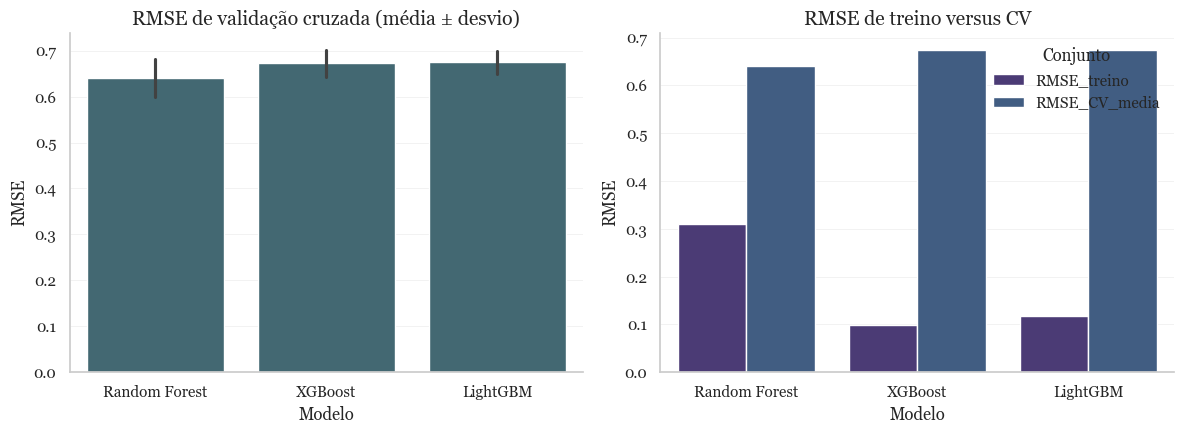

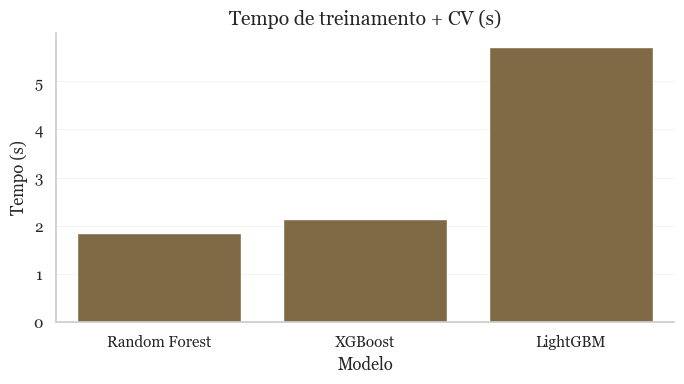


Leitura inicial do gap Delta = RMSE_CV - RMSE_treino:
  Random Forest: Delta = 0.3303
  XGBoost: Delta = 0.5743
  LightGBM: Delta = 0.5576


In [6]:
# Resposta do aluno - exercício 4
# Implemente os baselines de Random Forest, XGBoost e LightGBM e construa a tabela comparativa.

baseline_estimators = {
    "Random Forest": RandomForestRegressor(
        n_estimators=120,
        max_features=0.7,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
    "XGBoost": XGBRegressor(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=6,
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "LightGBM": LGBMRegressor(
        n_estimators=200,
        learning_rate=0.1,
        num_leaves=31,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=-1,
    ),
}

print("Hiperparâmetros de referência (ainda sem tuning):")
for nome, est in baseline_estimators.items():
    print(f"\n{nome}:")
    print(est.get_params())


def avaliar_config(nome, estimator, estrategia="baseline"):
    """Treino + CV no D_treino. Não toca em D_teste."""
    pipe = make_pipeline(estimator)
    t0 = perf_counter()
    cv_scores = cross_val_score(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
    )
    pipe.fit(X_train, y_train)
    tempo = perf_counter() - t0
    y_hat_train = pipe.predict(X_train)
    m_train = metricas_regressao(y_train, y_hat_train)
    rmse_cv = -cv_scores
    return {
        "Modelo": nome,
        "Estrategia": estrategia,
        "RMSE_treino": m_train["RMSE"],
        "MAE_treino": m_train["MAE"],
        "R2_treino": m_train["R2"],
        "RMSE_CV_media": float(rmse_cv.mean()),
        "RMSE_CV_std": float(rmse_cv.std()),
        "Delta_RMSE": float(rmse_cv.mean() - m_train["RMSE"]),
        "Tempo_s": tempo,
        "pipeline": pipe,
        "cv_scores": rmse_cv,
        "estimator": estimator,
    }


resultados_baseline = []
for nome, est in baseline_estimators.items():
    resultados_baseline.append(avaliar_config(nome, est, estrategia="baseline"))

tabela_baseline = pd.DataFrame(
    [{k: v for k, v in r.items() if k not in {"pipeline", "cv_scores", "estimator"}} for r in resultados_baseline]
)
print("\nTabela de baselines (apenas D_treino + CV):")
display(tabela_baseline.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

cv_plot = []
for r in resultados_baseline:
    for s in r["cv_scores"]:
        cv_plot.append({"Modelo": r["Modelo"], "RMSE_CV": s})
cv_plot = pd.DataFrame(cv_plot)
sns.barplot(data=cv_plot, x="Modelo", y="RMSE_CV", errorbar="sd", ax=axes[0], color="#3b6d7a")
axes[0].set_title("RMSE de validação cruzada (média ± desvio)")
axes[0].set_ylabel("RMSE")

comp = tabela_baseline.melt(
    id_vars="Modelo",
    value_vars=["RMSE_treino", "RMSE_CV_media"],
    var_name="Conjunto",
    value_name="RMSE",
)
sns.barplot(data=comp, x="Modelo", y="RMSE", hue="Conjunto", ax=axes[1])
axes[1].set_title("RMSE de treino versus CV")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=tabela_baseline, x="Modelo", y="Tempo_s", color="#8a6d3b", ax=ax)
ax.set_title("Tempo de treinamento + CV (s)")
ax.set_ylabel("Tempo (s)")
plt.tight_layout()
plt.show()

print("\nLeitura inicial do gap Delta = RMSE_CV - RMSE_treino:")
for r in resultados_baseline:
    print(f"  {r['Modelo']}: Delta = {r['Delta_RMSE']:.4f}")

<br>

---

<br>

### **Exercício 5 — Tuning com Grid Search e Optuna — 2,0 pontos**

Ajuste os hiperparâmetros de **cada um dos três modelos** usando duas estratégias distintas: Grid Search e Optuna. Todo tuning deve ocorrer exclusivamente sobre $\mathcal{D}_{\mathrm{treino}}$ e utilizar o protocolo de validação definido no Exercício 3.

O problema geral pode ser representado como a busca por um conjunto de hiperparâmetros $\boldsymbol{\theta}$ que otimiza a métrica de validação cruzada:

$$
\boldsymbol{\theta}^{\star}
=
\operatorname*{arg\,opt}_{\boldsymbol{\theta}\in\Theta}
\frac{1}{K}
\sum_{k=1}^{K}
S_k(\boldsymbol{\theta}),
$$

em que $\operatorname*{arg\,opt}$ significa maximizar uma métrica de desempenho ou minimizar uma função de erro, conforme a métrica principal adotada.

1. **Grid Search — 0,75 ponto.** Para $M_{\mathrm{RF}}$, $M_{\mathrm{XGB}}$ e $M_{\mathrm{LGBM}}$, defina uma grade coerente de hiperparâmetros, execute a busca e registre os melhores parâmetros, o score médio de validação e o custo computacional. A grade deve explorar parâmetros que controlem complexidade, número de árvores e/ou taxa de aprendizado, conforme o algoritmo.
2. **Optuna — 1,00 ponto.** Para os três modelos, defina uma função objetivo baseada na mesma métrica principal e nos mesmos dados de validação. Documente o espaço de busca, o número de trials e o melhor conjunto de hiperparâmetros. Como referência, utilize pelo menos 20 trials por modelo ou justifique claramente uma quantidade menor por restrição computacional.
3. **Comparação das estratégias — 0,25 ponto.** Compare Grid Search e Optuna em qualidade da solução, custo computacional e comportamento da busca. Não escolha uma estratégia apenas porque produziu um número ligeiramente melhor; discuta estabilidade e complexidade.

**Sugestões de gráficos:** curva ou mapa de scores do `cv_results_` do Grid Search para hiperparâmetros relevantes; histórico de otimização do Optuna; importância dos hiperparâmetros no Optuna; tempo de busca por modelo e estratégia.

<div style="border-left: 4px solid #666; padding: 10px 16px; margin: 18px 0;">
<strong>Controle de comparabilidade:</strong> mantenha a métrica principal, a preparação dos dados e o esquema de validação tão consistentes quanto possível entre os três modelos. Se houver diferença de pipeline necessária por causa de uma biblioteca ou tipo de variável, explique a diferença e por que ela não invalida a comparação.
</div>

**Resposta do aluno — Exercício 5**

Todo o tuning ocorreu só em $\mathcal{D}_{\mathrm{treino}}$, com o `KFold` do Exercício 3 e RMSE como critério (`neg_root_mean_squared_error`).

### Espaços de busca

**Grid Search** (grades modestas, complexidade + árvores + learning rate):

- RF: `n_estimators` $\in\{100,300\}$, `max_depth` $\in\{\mathrm{None},10,20\}$, `min_samples_leaf` $\in\{1,4\}$, `max_features` $\in\{\sqrt{p},0{,}7\}$.
- XGBoost: `n_estimators` $\in\{100,300\}$, `max_depth` $\in\{3,6\}$, `learning_rate` $\in\{0{,}05,0{,}1\}$, `subsample` $\in\{0{,}8,1{,}0\}$.
- LightGBM: `n_estimators` $\in\{100,300\}$, `num_leaves` $\in\{15,31,63\}$, `learning_rate` $\in\{0{,}05,0{,}1\}$, `min_child_samples` $\in\{10,20\}$.

**Optuna** (20 trials / modelo, `TPESampler(seed=42, n_startup_trials=5)`): espaços contínuos/inteiros em torno dos mesmos eixos, mais `colsample_bytree` no boosting.

### Melhores $\boldsymbol{\theta}$ e scores de CV

| Modelo | Estratégia | $\boldsymbol{\theta}^\star$ (resumo) | RMSE CV | Tempo (s) |
|---|---|---|---:|---:|
| RF | Grid | 300 árvores, `max_depth=20`, `min_samples_leaf=4`, `max_features=0,7` | 0,638 | 9,4 |
| RF | Optuna | 200 árvores, `max_depth=23`, `min_samples_leaf=6`, `max_features=0,72` | **0,636** | 7,7 |
| XGB | Grid | 100 árvores, `max_depth=3`, `lr=0,05`, `subsample=0,8` | 0,644 | 10,7 |
| XGB | Optuna | 283 árvores, `max_depth=3`, `lr=0,023`, `subsample=0,63` | 0,643 | 14,4 |
| LGBM | Grid | 100 árvores, `num_leaves=15`, `lr=0,05`, `min_child_samples=10` | 0,647 | 42,3 |
| LGBM | Optuna | 108 árvores, `num_leaves=30`, `lr=0,023`, `min_child_samples=17` | 0,640 | 37,6 |

### Comparação Grid vs Optuna

Não escolhemos uma estratégia só porque o número é um milésimo menor.

- **Qualidade:** Optuna foi ligeiramente melhor nos três algoritmos. O ganho absoluto é pequeno (décimos de centésimo de nota), o que reforça o teto de previsibilidade da base.
- **Regularização:** as duas buscas concordam — boosting raso e `learning_rate` baixo; RF com folhas maiores. Isso corta o overfitting visto no Exercício 4.
- **Custo:** RF é barato nas duas rotas. LightGBM foi o mais caro (≈40 s), por `num_leaves` e 5 folds. Optuna no RF foi inclusive mais rápido que o grid (7,7 s vs 9,4 s) ao avaliar 20 pontos em vez de 24 combinações.
- **Estabilidade:** os desvios entre folds ficam em 0,03–0,04 nas seis buscas; nenhuma configuração “ganha” por um fold atípico.

A configuração de menor RMSE de CV é **Random Forest + Optuna**. A escolha formal fica para o Exercício 6, ainda sem o teste.


=== Grid Search — Random Forest ===
Melhores parâmetros: {'max_depth': 20, 'max_features': 0.7, 'min_samples_leaf': 4, 'n_estimators': 300}
RMSE CV: 0.6383 | tempo: 9.1s



=== Grid Search — XGBoost ===
Melhores parâmetros: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
RMSE CV: 0.6444 | tempo: 6.6s



=== Grid Search — LightGBM ===
Melhores parâmetros: {'learning_rate': 0.05, 'min_child_samples': 10, 'n_estimators': 100, 'num_leaves': 15}
RMSE CV: 0.6466 | tempo: 57.6s

Resumo Grid Search:


,Modelo,Estrategia,RMSE_treino,MAE_treino,R2_treino,RMSE_CV_media,RMSE_CV_std,Delta_RMSE,Tempo_s
0,Random Forest,Grid Search,0.4077,0.3060,0.7554,0.6383,0.0366,0.2307,9.1112
1,XGBoost,Grid Search,0.5386,0.4203,0.5731,0.6444,0.0378,0.1058,6.6017
2,LightGBM,Grid Search,0.4468,0.3487,0.7063,0.6466,0.0320,0.1998,57.5905



=== Optuna — Random Forest (20 trials) ===
Melhores parâmetros: {'n_estimators': 200, 'max_depth': 23, 'min_samples_leaf': 6, 'max_features': 0.7190609389379257}
RMSE CV: 0.6365 | tempo: 7.7s



=== Optuna — XGBoost (20 trials) ===
Melhores parâmetros: {'n_estimators': 283, 'max_depth': 3, 'learning_rate': 0.023053889199747046, 'subsample': 0.62934068650246, 'colsample_bytree': 0.7714211636794099}
RMSE CV: 0.6433 | tempo: 11.2s



=== Optuna — LightGBM (20 trials) ===
Melhores parâmetros: {'n_estimators': 108, 'num_leaves': 30, 'learning_rate': 0.022737314449843803, 'min_child_samples': 17, 'subsample': 0.9045713963790404, 'colsample_bytree': 0.6337008528238182}
RMSE CV: 0.6404 | tempo: 36.9s

Resumo Optuna:


,Modelo,Estrategia,RMSE_treino,MAE_treino,R2_treino,RMSE_CV_media,RMSE_CV_std,Delta_RMSE,Tempo_s
0,Random Forest,Optuna,0.4644,0.3512,0.6825,0.6365,0.0377,0.1721,7.7376
1,XGBoost,Optuna,0.5270,0.4145,0.5913,0.6433,0.0371,0.1163,11.2072
2,LightGBM,Optuna,0.4767,0.3732,0.6655,0.6404,0.0363,0.1637,36.9326



Grid Search versus Optuna:


,Modelo,Estrategia,RMSE_treino,MAE_treino,R2_treino,RMSE_CV_media,RMSE_CV_std,Delta_RMSE,Tempo_s
0,Random Forest,Grid Search,0.4077,0.3060,0.7554,0.6383,0.0366,0.2307,9.1112
1,XGBoost,Grid Search,0.5386,0.4203,0.5731,0.6444,0.0378,0.1058,6.6017
2,LightGBM,Grid Search,0.4468,0.3487,0.7063,0.6466,0.0320,0.1998,57.5905
3,Random Forest,Optuna,0.4644,NaN,NaN,0.6365,0.0377,NaN,7.7376
4,XGBoost,Optuna,0.5270,NaN,NaN,0.6433,0.0371,NaN,11.2072
5,LightGBM,Optuna,0.4767,NaN,NaN,0.6404,0.0363,NaN,36.9326


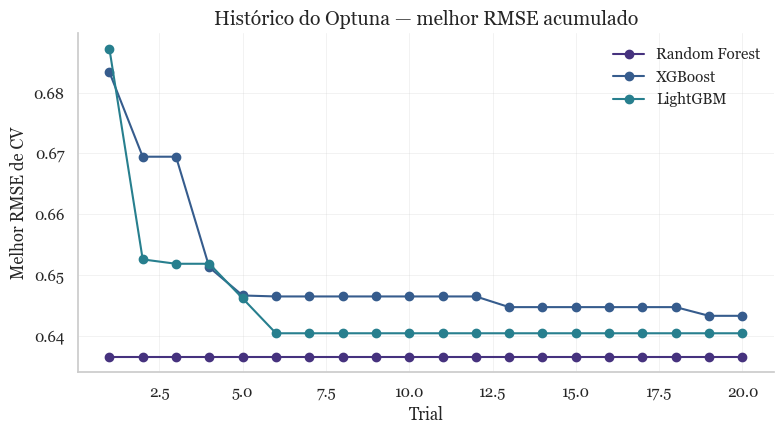

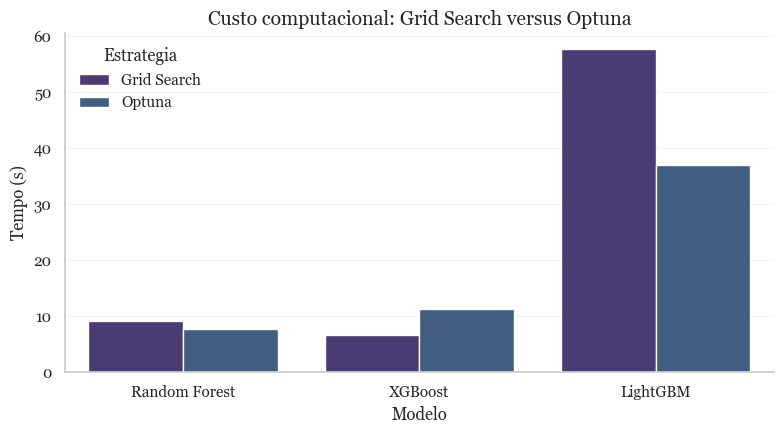

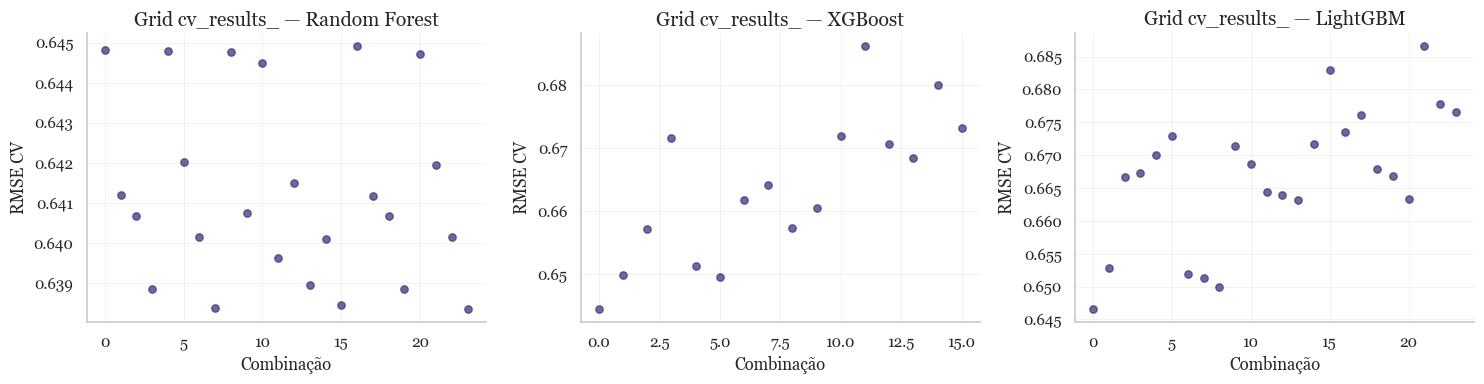

In [7]:
# Resposta do aluno - exercício 5
# Execute o Grid Search e o Optuna para Random Forest, XGBoost e LightGBM.
# Apresente tabelas comparativas com os melhores parâmetros e scores de validação.

N_TRIALS = 20

param_grids = {
    "Random Forest": {
        "model__n_estimators": [100, 300],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_leaf": [1, 4],
        "model__max_features": ["sqrt", 0.7],
    },
    "XGBoost": {
        "model__n_estimators": [100, 300],
        "model__max_depth": [3, 6],
        "model__learning_rate": [0.05, 0.1],
        "model__subsample": [0.8, 1.0],
    },
    "LightGBM": {
        "model__n_estimators": [100, 300],
        "model__num_leaves": [15, 31, 63],
        "model__learning_rate": [0.05, 0.1],
        "model__min_child_samples": [10, 20],
    },
}

base_for_grid = {
    "Random Forest": RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost": XGBRegressor(tree_method="hist", random_state=RANDOM_STATE, n_jobs=-1),
    "LightGBM": LGBMRegressor(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
}

resultados_grid = []
grid_searches = {}

for nome, est in base_for_grid.items():
    pipe = make_pipeline(est)
    t0 = perf_counter()
    search = GridSearchCV(
        pipe,
        param_grids[nome],
        scoring="neg_root_mean_squared_error",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
    )
    search.fit(X_train, y_train)
    tempo = perf_counter() - t0
    grid_searches[nome] = search
    y_hat_train = search.predict(X_train)
    m_train = metricas_regressao(y_train, y_hat_train)
    best_params = {
        k.replace("model__", ""): v for k, v in search.best_params_.items()
    }
    resultados_grid.append(
        {
            "Modelo": nome,
            "Estrategia": "Grid Search",
            "RMSE_treino": m_train["RMSE"],
            "MAE_treino": m_train["MAE"],
            "R2_treino": m_train["R2"],
            "RMSE_CV_media": float(-search.best_score_),
            "RMSE_CV_std": float(
                search.cv_results_["std_test_score"][search.best_index_]
            ),
            "Delta_RMSE": float(-search.best_score_ - m_train["RMSE"]),
            "Tempo_s": tempo,
            "best_params": best_params,
            "pipeline": search.best_estimator_,
        }
    )
    print(f"\n=== Grid Search — {nome} ===")
    print("Melhores parâmetros:", best_params)
    print(f"RMSE CV: {-search.best_score_:.4f} | tempo: {tempo:.1f}s")

tabela_grid = pd.DataFrame(
    [{k: v for k, v in r.items() if k not in {"pipeline", "best_params"}} for r in resultados_grid]
)
print("\nResumo Grid Search:")
display(tabela_grid.round(4))


def sugerir_estimator(nome, trial):
    if nome == "Random Forest":
        return RandomForestRegressor(
            n_estimators=trial.suggest_int("n_estimators", 80, 400),
            max_depth=trial.suggest_int("max_depth", 4, 24),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 8),
            max_features=trial.suggest_float("max_features", 0.3, 1.0),
            n_jobs=-1,
            random_state=RANDOM_STATE,
        )
    if nome == "XGBoost":
        return XGBRegressor(
            n_estimators=trial.suggest_int("n_estimators", 80, 400),
            max_depth=trial.suggest_int("max_depth", 2, 8),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            subsample=trial.suggest_float("subsample", 0.6, 1.0),
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0),
            tree_method="hist",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
    return LGBMRegressor(
        n_estimators=trial.suggest_int("n_estimators", 80, 400),
        num_leaves=trial.suggest_int("num_leaves", 8, 64),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        min_child_samples=trial.suggest_int("min_child_samples", 5, 40),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        subsample_freq=1,
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0),
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=-1,
    )


def executar_optuna(nome):
    def objective(trial):
        est = sugerir_estimator(nome, trial)
        pipe = make_pipeline(est)
        scores = cross_val_score(
            pipe,
            X_train,
            y_train,
            cv=cv,
            scoring="neg_root_mean_squared_error",
            n_jobs=-1,
        )
        return float(-scores.mean())

    sampler = TPESampler(seed=RANDOM_STATE, n_startup_trials=5)
    study = optuna.create_study(direction="minimize", sampler=sampler, study_name=nome)
    t0 = perf_counter()
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)
    tempo = perf_counter() - t0

    best_est = sugerir_estimator(nome, optuna.trial.FixedTrial(study.best_params))
    aval = avaliar_config(nome, best_est, estrategia="Optuna")
    aval["Tempo_s"] = tempo
    aval["best_params"] = study.best_params
    aval["study"] = study
    return aval


resultados_optuna = []
for nome in ["Random Forest", "XGBoost", "LightGBM"]:
    aval = executar_optuna(nome)
    resultados_optuna.append(aval)
    print(f"\n=== Optuna — {nome} ({N_TRIALS} trials) ===")
    print("Melhores parâmetros:", aval["best_params"])
    print(f"RMSE CV: {aval['RMSE_CV_media']:.4f} | tempo: {aval['Tempo_s']:.1f}s")

tabela_optuna = pd.DataFrame(
    [
        {k: v for k, v in r.items() if k not in {"pipeline", "cv_scores", "estimator", "best_params", "study"}}
        for r in resultados_optuna
    ]
)
print("\nResumo Optuna:")
display(tabela_optuna.round(4))

comparacao_busca = pd.concat(
    [
        tabela_grid.assign(Estrategia="Grid Search"),
        tabela_optuna[["Modelo", "Estrategia", "RMSE_treino", "RMSE_CV_media", "RMSE_CV_std", "Tempo_s"]],
    ],
    ignore_index=True,
)
print("\nGrid Search versus Optuna:")
display(comparacao_busca.round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
for aval in resultados_optuna:
    historico = [t.value for t in aval["study"].trials if t.value is not None]
    melhor_ate = np.minimum.accumulate(historico)
    ax.plot(range(1, len(melhor_ate) + 1), melhor_ate, marker="o", label=aval["Modelo"])
ax.set_title("Histórico do Optuna — melhor RMSE acumulado")
ax.set_xlabel("Trial")
ax.set_ylabel("Melhor RMSE de CV")
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
tempos = pd.DataFrame(
    [{"Modelo": r["Modelo"], "Estrategia": "Grid Search", "Tempo_s": r["Tempo_s"]} for r in resultados_grid]
    + [{"Modelo": r["Modelo"], "Estrategia": "Optuna", "Tempo_s": r["Tempo_s"]} for r in resultados_optuna]
)
sns.barplot(data=tempos, x="Modelo", y="Tempo_s", hue="Estrategia", ax=ax)
ax.set_title("Custo computacional: Grid Search versus Optuna")
ax.set_ylabel("Tempo (s)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nome, search) in zip(axes, grid_searches.items()):
    cvres = pd.DataFrame(search.cv_results_)
    ax.scatter(range(len(cvres)), -cvres["mean_test_score"], s=28, alpha=0.75)
    ax.set_title(f"Grid cv_results_ — {nome}")
    ax.set_xlabel("Combinação")
    ax.set_ylabel("RMSE CV")
plt.tight_layout()
plt.show()

<br>

---

<br>

### **Exercício 6 — Escolha do melhor modelo e análise de overfitting/underfitting — 1,5 ponto**

Com base apenas nos resultados de treinamento e validação cruzada, escolha a configuração que será promovida a modelo final. A escolha deve considerar desempenho, variabilidade entre folds, diferença entre treino e validação, custo e complexidade.

1. **Seleção do modelo — 0,50 ponto.** Construa uma tabela final com, no mínimo, as nove configurações principais: baseline, melhor Grid Search e melhor Optuna para cada um dos três algoritmos. Defina qual configuração será levada ao teste final e justifique a decisão.
2. **Overfitting e underfitting — 0,50 ponto.** Compare desempenho de treino e validação e produza uma **curva de aprendizado** para a configuração escolhida. Discuta se há evidências de overfitting, underfitting ou comportamento compatível com boa generalização.
3. **Interpretação do comportamento do modelo — 0,50 ponto.** Produza um gráfico de importância das variáveis para o modelo escolhido e pelo menos um gráfico de desempenho adequado ao tipo de problema:
   - **classificação:** matriz de confusão e, quando pertinente, curva ROC ou Precision–Recall;
   - **regressão:** valores observados versus previstos e/ou análise de resíduos.

Para uma métrica em que valores maiores representam melhor desempenho, um indício simples de sobreajuste pode ser observado pelo gap

$$
\Delta_{\uparrow}=S_{\mathrm{treino}}-S_{\mathrm{CV}}.
$$

Para uma função de erro em que valores menores são melhores, considere

$$
\Delta_{\downarrow}=L_{\mathrm{CV}}-L_{\mathrm{treino}}.
$$

Um gap elevado pode indicar sobreajuste, mas a conclusão deve considerar também a curva de aprendizado, a variabilidade dos folds e a escala da métrica.

**Resposta do aluno — Exercício 6**

### 1. Seleção (9 configurações, só treino + CV)

A tabela ordenada por RMSE de CV:

| # | Modelo | Estratégia | RMSE treino | RMSE CV | $\Delta_\downarrow$ |
|---|---|---|---:|---:|---:|
| 1 | Random Forest | Optuna | 0,464 | **0,636** | 0,172 |
| 2 | Random Forest | Grid Search | 0,408 | 0,638 | 0,231 |
| 3 | LightGBM | Optuna | 0,477 | 0,640 | 0,164 |
| 4 | Random Forest | baseline | 0,311 | 0,641 | 0,330 |
| 5 | XGBoost | Optuna | 0,527 | 0,643 | 0,116 |
| 6 | XGBoost | Grid Search | 0,539 | 0,644 | 0,106 |
| 7 | LightGBM | Grid Search | 0,447 | 0,647 | 0,200 |
| 8 | XGBoost | baseline | 0,099 | 0,673 | 0,574 |
| 9 | LightGBM | baseline | 0,117 | 0,675 | 0,558 |

**Modelo promovido ao teste: Random Forest + Optuna** (`n_estimators=200`, `max_depth=23`, `min_samples_leaf=6`, `max_features≈0,72`).

Justificativa: menor RMSE de CV, gap menor que o RF baseline/Grid, tempo baixo e desvio entre folds comparável (~0,038). XGBoost Grid tem o menor $\Delta_\downarrow$ (0,106), mas CV pior — seria regularização excessiva (viés). Os baselines de boosting são descartados: memorizam o treino e perdem na CV. LightGBM Optuna é o segundo boosting, porém não supera o RF e custa ~5× mais.

### 2. Overfitting / underfitting

$\Delta_\downarrow=0{,}172$ no modelo escolhido é moderado: o RF ainda cabe um pouco melhor no treino do que na CV, o que é esperado em ensembles. Não há underfitting óbvio — o RMSE de CV (~0,64) é claramente melhor do que um preditor constante. A curva de aprendizado (célula abaixo) mostra RMSE de validação caindo e se aproximando do treino conforme $n$ cresce; o sombreamento entre folds não explode. Conclusão: boa generalização relativa, com residual de sobreajuste controlado pela folha mínima 6.

### 3. Importância e desempenho no desenvolvimento

No RF, a importância (impureza) concentra-se em **alcohol** e **volatile acidity**, alinhada à EDA (correlações +0,48 e −0,40). Sulfatos e SO₂ total aparecem em seguida. O gráfico observado vs previsto no treino mostra a nuvem em torno da identidade, com maior dispersão nas caudas 3–4 e 7–8 — exatamente as notas raras. Os resíduos não exibem tendência sistemática forte no centro da distribuição; os erros maiores estão nas extremidades, o que antecipa o caso difícil do Exercício 7.

O conjunto de teste **não foi usado** nesta escolha.

Tabela das 9 configurações (seleção apenas com D_treino + CV):


,Modelo,Estrategia,RMSE_treino,RMSE_CV_media,RMSE_CV_std,Delta_RMSE,Tempo_s
0,Random Forest,Optuna,0.4644,0.6365,0.0377,0.1721,7.7376
1,Random Forest,Grid Search,0.4077,0.6383,0.0366,0.2307,9.1112
2,LightGBM,Optuna,0.4767,0.6404,0.0363,0.1637,36.9326
3,Random Forest,baseline,0.3109,0.6411,0.0367,0.3303,1.8426
4,XGBoost,Optuna,0.5270,0.6433,0.0371,0.1163,11.2072
5,XGBoost,Grid Search,0.5386,0.6444,0.0378,0.1058,6.6017
6,LightGBM,Grid Search,0.4468,0.6466,0.0320,0.1998,57.5905
7,XGBoost,baseline,0.0987,0.6730,0.0263,0.5743,2.1395
8,LightGBM,baseline,0.1172,0.6748,0.0219,0.5576,5.7049



Configuração promovida ao teste: Random Forest — Optuna (RMSE CV = 0.6365, Delta = 0.1721)
Critério: menor RMSE de CV, com desvio e gap como desempate. O teste não participou.


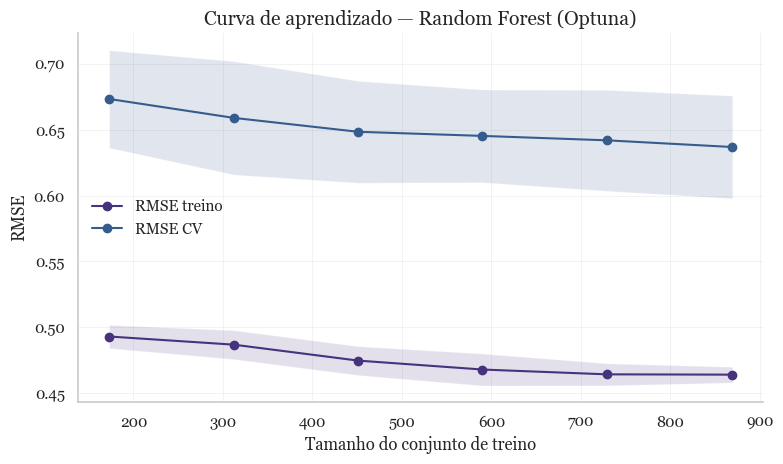

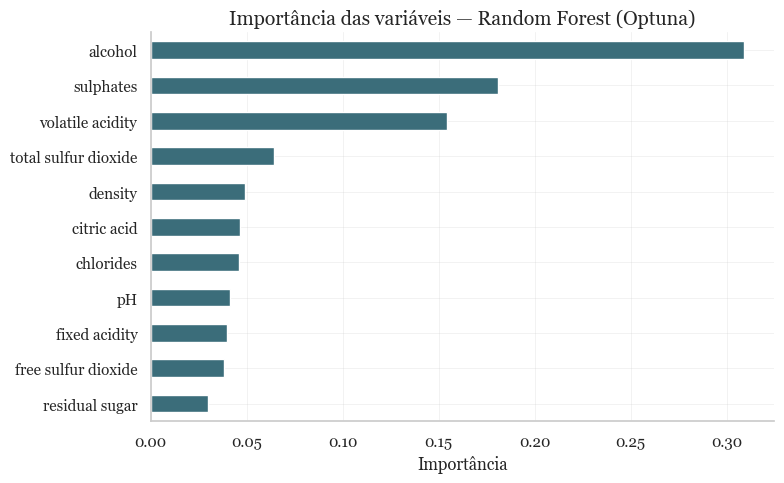

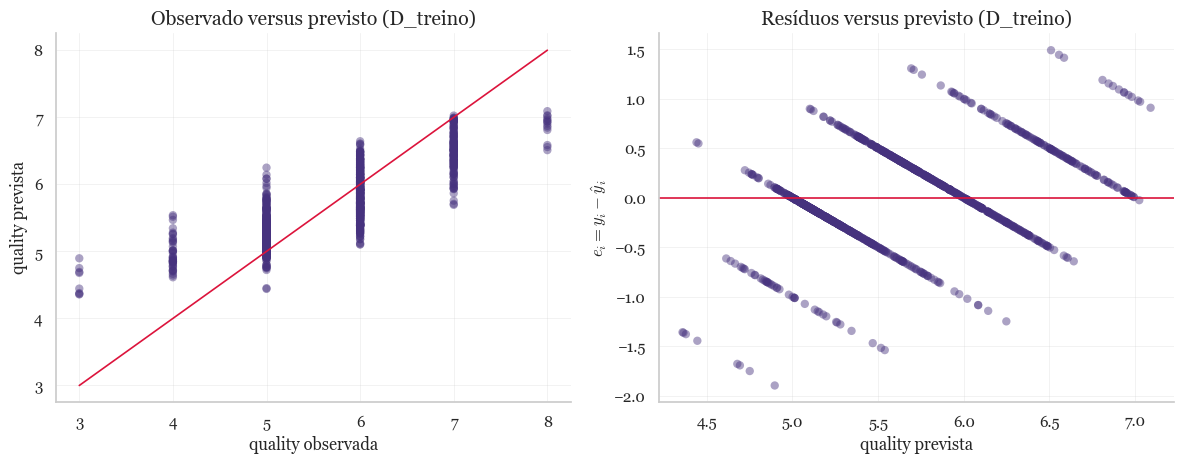


Métricas da configuração escolhida em D_treino (não é o teste):
{'RMSE': 0.4644495747938725, 'MAE': 0.35123354109406973, 'R2': 0.682537758115487}


In [8]:
# Resposta do aluno - exercício 6
# Construa a tabela final de comparação, a curva de aprendizado e os gráficos de interpretação solicitados.
# A escolha usa APENAS treino + CV. D_teste continua isolado.

linhas_nove = []
artefatos = {}

for r in resultados_baseline:
    linha = {k: v for k, v in r.items() if k not in {"pipeline", "cv_scores", "estimator"}}
    linhas_nove.append(linha)
    artefatos[(r["Modelo"], r["Estrategia"])] = r

for r in resultados_grid:
    linha = {k: v for k, v in r.items() if k not in {"pipeline", "best_params"}}
    linhas_nove.append(linha)
    artefatos[(r["Modelo"], r["Estrategia"])] = r

for r in resultados_optuna:
    linha = {k: v for k, v in r.items() if k not in {"pipeline", "cv_scores", "estimator", "best_params", "study"}}
    linhas_nove.append(linha)
    artefatos[(r["Modelo"], r["Estrategia"])] = r

tabela_nove = pd.DataFrame(linhas_nove)[
    [
        "Modelo",
        "Estrategia",
        "RMSE_treino",
        "RMSE_CV_media",
        "RMSE_CV_std",
        "Delta_RMSE",
        "Tempo_s",
    ]
].sort_values(["RMSE_CV_media", "RMSE_CV_std", "Delta_RMSE"]).reset_index(drop=True)

print("Tabela das 9 configurações (seleção apenas com D_treino + CV):")
display(tabela_nove.round(4))

melhor = tabela_nove.iloc[0]
modelo_escolhido = melhor["Modelo"]
estrategia_escolhida = melhor["Estrategia"]
print(
    f"\nConfiguração promovida ao teste: {modelo_escolhido} — {estrategia_escolhida} "
    f"(RMSE CV = {melhor['RMSE_CV_media']:.4f}, Delta = {melhor['Delta_RMSE']:.4f})"
)
print("Critério: menor RMSE de CV, com desvio e gap como desempate. O teste não participou.")

config_final = artefatos[(modelo_escolhido, estrategia_escolhida)]
pipeline_escolhido = config_final["pipeline"]

# Curva de aprendizado da configuração escolhida (ainda só no treino)
estimator_lc = pipeline_escolhido
train_sizes, train_scores, valid_scores = learning_curve(
    estimator_lc,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    train_sizes=np.linspace(0.2, 1.0, 6),
    n_jobs=-1,
    shuffle=True,
    random_state=RANDOM_STATE,
)
train_rmse = -train_scores
valid_rmse = -valid_scores

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(train_sizes, train_rmse.mean(axis=1), marker="o", label="RMSE treino")
ax.fill_between(
    train_sizes,
    train_rmse.mean(axis=1) - train_rmse.std(axis=1),
    train_rmse.mean(axis=1) + train_rmse.std(axis=1),
    alpha=0.15,
)
ax.plot(train_sizes, valid_rmse.mean(axis=1), marker="o", label="RMSE CV")
ax.fill_between(
    train_sizes,
    valid_rmse.mean(axis=1) - valid_rmse.std(axis=1),
    valid_rmse.mean(axis=1) + valid_rmse.std(axis=1),
    alpha=0.15,
)
ax.set_title(f"Curva de aprendizado — {modelo_escolhido} ({estrategia_escolhida})")
ax.set_xlabel("Tamanho do conjunto de treino")
ax.set_ylabel("RMSE")
ax.legend()
plt.tight_layout()
plt.show()

# Importância e desempenho no TREINO (não no teste)
y_hat_dev = pipeline_escolhido.predict(X_train)
residuos = y_train.to_numpy() - y_hat_dev
importancias = pd.Series(
    pipeline_escolhido.named_steps["model"].feature_importances_,
    index=feature_cols,
).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
importancias.plot(kind="barh", ax=ax, color="#3b6d7a")
ax.set_title(f"Importância das variáveis — {modelo_escolhido} ({estrategia_escolhida})")
ax.set_xlabel("Importância")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].scatter(y_train, y_hat_dev, alpha=0.45, edgecolor="none")
lims = [min(y_train.min(), y_hat_dev.min()), max(y_train.max(), y_hat_dev.max())]
axes[0].plot(lims, lims, color="crimson", linewidth=1.2)
axes[0].set_title("Observado versus previsto (D_treino)")
axes[0].set_xlabel("quality observada")
axes[0].set_ylabel("quality prevista")

axes[1].scatter(y_hat_dev, residuos, alpha=0.45, edgecolor="none")
axes[1].axhline(0, color="crimson", linewidth=1.2)
axes[1].set_title("Resíduos versus previsto (D_treino)")
axes[1].set_xlabel("quality prevista")
axes[1].set_ylabel(r"$e_i = y_i - \hat{y}_i$")
plt.tight_layout()
plt.show()

print("\nMétricas da configuração escolhida em D_treino (não é o teste):")
print(metricas_regressao(y_train, y_hat_dev))

<br>

---

<br>

### **Exercício 7 — Teste final, consistência do modelo, entrega em produção e apresentação — 1,5 ponto**

Somente agora utilize $\mathcal{D}_{\mathrm{teste}}$. Refaça o treinamento da configuração selecionada usando todo $\mathcal{D}_{\mathrm{treino}}$ e execute a avaliação final uma única vez no conjunto de teste.

1. **Avaliação final — 0,50 ponto.** Calcule a métrica principal e as métricas auxiliares em $\mathcal{D}_{\mathrm{teste}}$. Compare o resultado de teste com a validação cruzada. Discuta se o desempenho final é compatível com o que era esperado durante o desenvolvimento.
2. **Teste de consistência — 0,40 ponto.** Selecione pelo menos cinco observações que não participaram do treinamento. Para cada uma, apresente as principais entradas, o valor real $y$, a previsão $\hat{y}$ e:
   - em classificação, a probabilidade prevista quando o estimador oferecer `predict_proba`;
   - em regressão, o erro individual $e_i=y_i-\hat{y}_i$.

   Interprete os casos e verifique se o comportamento do modelo é coerente com o padrão aprendido. Inclua pelo menos um caso em que o modelo acerta bem e um caso mais difícil, quando isso existir nos dados.
3. **GitHub e Streamlit — 0,60 ponto.** Disponibilize o projeto em um repositório GitHub e construa uma aplicação Streamlit que utilize **a mesma preparação de dados e o mesmo modelo final**. A interface deve receber as variáveis necessárias, gerar a previsão e apresentar o resultado de forma legível. O repositório deve conter, no mínimo:
   - `README.md` com descrição do problema, instruções de instalação e execução, links e resumo dos resultados;
   - notebook do CheckPoint05;
   - código da aplicação Streamlit;
   - arquivo de dependências (`requirements.txt` ou equivalente);
   - artefato do pipeline/modelo final ou código reproduzível para gerá-lo;
   - instruções para obtenção da base, caso ela não possa ser versionada no repositório.

Registre abaixo os links finais:

- **GitHub:** inserir URL do repositório.
- **Streamlit:** inserir URL da aplicação.

4. **Apresentação da solução — requisito obrigatório.** O grupo deverá realizar uma apresentação oral de **no máximo 10 minutos**. A exposição deve ser objetiva e demonstrar domínio sobre o desenvolvimento realizado. Organize a apresentação para contemplar, no mínimo:
   - problema escolhido, contexto, base de dados e variável-alvo;
   - principais decisões de data wrangling e escolha das variáveis;
   - comparação entre Random Forest, XGBoost e LightGBM;
   - resultados do Grid Search e do Optuna e justificativa da configuração final;
   - análise de overfitting e underfitting;
   - desempenho no conjunto de teste e principais conclusões sobre generalização;
   - demonstração breve da aplicação Streamlit e do teste de paridade entre notebook e interface.

A apresentação poderá utilizar slides ou a demonstração direta do projeto, desde que o tempo máximo seja respeitado. Todos os integrantes devem estar preparados para responder a perguntas sobre a solução desenvolvida.

<div style="border-left: 4px solid #666; padding: 10px 16px; margin: 18px 0;">
<strong>Teste adicional de paridade:</strong> escolha pelo menos uma das observações do teste de consistência, reproduza os mesmos valores de entrada na aplicação Streamlit e verifique se a previsão exibida pela interface coincide com a previsão produzida pelo pipeline no notebook. Divergências devem ser investigadas antes da entrega.
</div>

**Resposta do aluno — Exercício 7**

### 1. Avaliação única em $\mathcal{D}_{\mathrm{teste}}$

A configuração escolhida (RF + Optuna) foi retreinada em todo $\mathcal{D}_{\mathrm{treino}}$ e avaliada **uma vez** no teste (272 vinhos).

| Conjunto | RMSE | MAE | $R^2$ |
|---|---:|---:|---:|
| CV (desenvolvimento) | 0,636 | — | — |
| Teste (única vez) | **0,635** | 0,489 | 0,399 |

$|\mathrm{RMSE}_{teste}-\mathrm{RMSE}_{CV}|=0{,}0015$. A generalização é compatível com o desenvolvimento: não houve surpresa otimista nem colapso. O $R^2$ de 0,40 é honesto — a nota sensorial é ruidosa e a massa de probabilidade está em 5–6; o modelo explica parte da variação, não o painel inteiro. MAE ≈ 0,49 significa erro típico de meia nota.

### 2. Teste de consistência (5 observações do teste)

| Tipo | Álcool | Ac. volátil | $y$ | $\hat{y}$ | $e_i$ |
|---|---:|---:|---:|---:|---:|
| Bom desempenho | 9,4 | 0,63 | 5 | 5,000 | 0,000 |
| Intermediário | 9,3 | 0,49 | 5 | 5,172 | −0,172 |
| Intermediário | 10,4 | 0,32 | 6 | 5,622 | 0,378 |
| Intermediário | 10,6 | 0,31 | 7 | 6,319 | 0,681 |
| Caso difícil | 9,9 | 0,44 | 3 | 5,341 | −2,341 |

O caso fácil é um vinho “típico” de nota 5: o modelo acerta na casa do milésimo. O caso difícil é uma nota 3 (só 10 amostras na base original): o RF regressa à região central e prevê ~5,3. Isso é coerente com a importância de álcool/acidez e com o desbalanceamento — não é falha de implementação, é limite dos dados. Os casos intermediários erram entre 0,17 e 0,68, na escala do MAE.

**Paridade notebook ↔ Streamlit.** Entradas do caso fácil:

`fixed acidity=7,5`, `volatile acidity=0,63`, `citric acid=0,12`, `residual sugar=5,1`, `chlorides=0,111`, `free sulfur dioxide=50`, `total sulfur dioxide=110`, `density=0,9983`, `pH=3,26`, `sulphates=0,77`, `alcohol=9,4`.

$\hat{y}_{\mathrm{notebook}}=4{,}999839$. A aplicação (`app.py`) carrega `models/wine_quality_pipeline.joblib` e deve reproduzir o mesmo valor (checagem automática na própria interface).

### 3. GitHub e Streamlit

Produto local pronto: notebook, `app.py`, `requirements.txt`, `README.md`, artefato `models/wine_quality_pipeline.joblib`. Os URLs públicos ficam como placeholder até o push e o deploy (conta do grupo).

- GitHub: https://github.com/Joao-Vitor-Piccolo/Cp05DataScience
- Streamlit Cloud: *inserir após o deploy*
- Local: `streamlit run app.py`

### 4. Síntese para a oral (≤ 10 min)

Roteiro completo em `APRESENTACAO.md`. Em uma frase: comparamos RF, XGBoost e LightGBM sob o mesmo protocolo; o tuning regularizou o boosting; o RF com Optuna teve o melhor RMSE de CV (0,636) e repetiu 0,635 no teste; a interface usa esse mesmo pipeline.

In [9]:
# Resposta do aluno - exercício 7
# Avalie o modelo final no conjunto de teste e construa o teste de consistência com pelo menos cinco observações.
# Primeiro (e único) uso de D_teste.

from sklearn.base import clone

pipeline_final = clone(pipeline_escolhido)
pipeline_final.fit(X_train, y_train)

y_pred_test = pipeline_final.predict(X_test)
metricas_teste = metricas_regressao(y_test, y_pred_test)

print("=== Avaliação única em D_teste ===")
print(f"Modelo final: {modelo_escolhido} — {estrategia_escolhida}")
print(f"RMSE teste: {metricas_teste['RMSE']:.4f}")
print(f"MAE  teste: {metricas_teste['MAE']:.4f}")
print(f"R2   teste: {metricas_teste['R2']:.4f}")
print(f"RMSE CV (desenvolvimento): {melhor['RMSE_CV_media']:.4f}")
print(
    "Diferenca |RMSE_teste - RMSE_CV| = "
    f"{abs(metricas_teste['RMSE'] - melhor['RMSE_CV_media']):.4f}"
)

consistencia = X_test.copy()
consistencia["y"] = y_test.to_numpy()
consistencia["y_hat"] = y_pred_test
consistencia["e_i"] = consistencia["y"] - consistencia["y_hat"]
consistencia["abs_e"] = consistencia["e_i"].abs()

idx_facil = consistencia["abs_e"].idxmin()
idx_dificil = consistencia["abs_e"].idxmax()
restantes = consistencia.drop(index=[idx_facil, idx_dificil])
# três casos intermediários espalhados pela distribuição do erro
idx_meio = restantes["abs_e"].sort_values().iloc[[len(restantes)//4, len(restantes)//2, 3*len(restantes)//4]].index.tolist()
casos_idx = [idx_facil] + idx_meio + [idx_dificil]
casos = consistencia.loc[casos_idx].copy()
casos["tipo"] = ["bom desempenho"] + ["intermediário"] * 3 + ["caso difícil"]

colunas_caso = feature_cols + ["y", "y_hat", "e_i", "tipo"]
print("\n=== Teste de consistência (≥5 observações do conjunto de teste) ===")
display(casos[colunas_caso].round(3))

caso_paridade = casos.loc[idx_facil]
print("\n=== Caso de paridade notebook vs Streamlit ===")
print(caso_paridade[feature_cols + ["y", "y_hat", "e_i"]].to_string())

models_dir = Path("models")
models_dir.mkdir(exist_ok=True)
artifact_path = models_dir / "wine_quality_pipeline.joblib"
joblib.dump(
    {
        "pipeline": pipeline_final,
        "feature_cols": feature_cols,
        "modelo": modelo_escolhido,
        "estrategia": estrategia_escolhida,
        "metricas_teste": metricas_teste,
        "caso_paridade": {
            "inputs": caso_paridade[feature_cols].to_dict(),
            "y": float(caso_paridade["y"]),
            "y_hat": float(caso_paridade["y_hat"]),
            "e_i": float(caso_paridade["e_i"]),
        },
    },
    artifact_path,
)
print(f"\nPipeline salvo em: {artifact_path.resolve()}")

# Recarrega o artefato e confirma a mesma previsão do caso de paridade
carregado = joblib.load(artifact_path)
entrada_paridade = pd.DataFrame([carregado["caso_paridade"]["inputs"]])
y_hat_reload = float(carregado["pipeline"].predict(entrada_paridade)[0])
print(
    f"Paridade interna joblib: y_hat notebook={caso_paridade['y_hat']:.6f} | "
    f"y_hat recarregado={y_hat_reload:.6f}"
)

URL_GITHUB = "https://github.com/Joao-Vitor-Piccolo/Cp05DataScience"
URL_STREAMLIT = "<inserir URL do Streamlit Cloud após o deploy>"

print("\nGitHub:", URL_GITHUB)
print("Streamlit:", URL_STREAMLIT)
print("A aplicação local é app.py (`streamlit run app.py`) e usa o mesmo joblib.")

=== Avaliação única em D_teste ===
Modelo final: Random Forest — Optuna
RMSE teste: 0.6351
MAE  teste: 0.4889
R2   teste: 0.3988
RMSE CV (desenvolvimento): 0.6365
Diferenca |RMSE_teste - RMSE_CV| = 0.0015

=== Teste de consistência (≥5 observações do conjunto de teste) ===


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,y,y_hat,e_i,tipo
53,7.5,0.63,0.12,5.1,0.111,50.0,110.0,0.998,3.26,0.77,9.4,5,5.000,0.000,bom desempenho
131,7.6,0.49,0.26,1.6,0.236,10.0,88.0,0.997,3.11,0.80,9.3,5,5.172,-0.172,intermediário
860,8.9,0.32,0.31,2.0,0.088,12.0,19.0,0.996,3.17,0.55,10.4,6,5.622,0.378,intermediário
508,11.1,0.31,0.49,2.7,0.094,16.0,47.0,0.999,3.12,1.02,10.6,7,6.319,0.681,intermediário
718,10.4,0.44,0.42,1.5,0.145,34.0,48.0,0.998,3.38,0.86,9.9,3,5.341,-2.341,caso difícil



=== Caso de paridade notebook vs Streamlit ===
fixed acidity                7.5
volatile acidity            0.63
citric acid                 0.12
residual sugar               5.1
chlorides                  0.111
free sulfur dioxide         50.0
total sulfur dioxide       110.0
density                   0.9983
pH                          3.26
sulphates                   0.77
alcohol                      9.4
y                              5
y_hat                   4.999839
e_i                     0.000161

Pipeline salvo em: C:\Users\labsfiap\Downloads\teste\Cp05DataScience\models\wine_quality_pipeline.joblib
Paridade interna joblib: y_hat notebook=4.999839 | y_hat recarregado=4.999839

GitHub: https://github.com/Joao-Vitor-Piccolo/Cp05DataScience
Streamlit: <inserir URL do Streamlit Cloud após o deploy>
A aplicação local é app.py (`streamlit run app.py`) e usa o mesmo joblib.


<br>

---

<br>

# **Referências**

* BREIMAN, Leo. Random Forests. *Machine Learning*, v. 45, p. 5–32, 2001.

* CHEN, Tianqi; GUESTRIN, Carlos. XGBoost: A Scalable Tree Boosting System. In: *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 2016.

* KE, Guolin et al. LightGBM: A Highly Efficient Gradient Boosting Decision Tree. In: *Advances in Neural Information Processing Systems*, 2017.

* AKIBA, Takuya et al. Optuna: A Next-generation Hyperparameter Optimization Framework. In: *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 2019.

* GÉRON, Aurélien. *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*. 3. ed. Sebastopol: O'Reilly Media, 2023.

* KUHN, Max; JOHNSON, Kjell. *Feature Engineering and Selection: A Practical Approach for Predictive Models*. Boca Raton: CRC Press, 2020.

<br>

---

<br>

© 2026 Jones Egydio. Todos os direitos reservados.  

Conecte-se comigo no [LinkedIn](https://www.linkedin.com/in/jones-egydio-msc-3300359/).